In [1]:
import torch
from torch_geometric.data import Data
from ase.io import read
from ase.neighborlist import neighbor_list
import numpy as np

c:\Users\23210\.conda\envs\ml-pytorch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def atoms_to_graph(atoms, cutoff=5.0):
    """
    将 ASE Atoms 对象转换为 PyTorch Geometric 的 Data 对象。
    并提取能量和力作为标签。
    """
    # 1. 节点特征 (Node Features)
    # 使用原子序数 (Z) 作为最基础的 embedding 索引
    # 形状: [N_atoms]
    atomic_numbers = torch.tensor(atoms.get_atomic_numbers(), dtype=torch.long)
    
    # 2. 边与边属性 (Edges & Edge Attributes) - 处理周期性边界条件 (PBC)
    # neighbor_list 会自动处理 PBC (Periodic Boundary Conditions)
    # 'ijS' 表示返回: i(source), j(target), S(shift vector)
    # 'D' 表示返回距离
    i, j, S, D = neighbor_list('ijSD', atoms, cutoff)
    
    # 构建边索引 [2, N_edges]
    edge_index = torch.stack([torch.tensor(i, dtype=torch.long), 
                              torch.tensor(j, dtype=torch.long)], dim=0)
    
    # 构建边特征 (这里只使用标量距离，高阶模型可能需要矢量 vector)
    # 形状: [N_edges, 1]
    edge_attr = torch.tensor(D, dtype=torch.float).unsqueeze(1)
    
    # (可选) 如果模型需要相对位移矢量 vector (r_j - r_i)，这对等变网络很重要
    # vectors = atoms.positions[j] - atoms.positions[i] + np.dot(S, atoms.get_cell())
    
    # 3. 提取标签 (Labels): 能量和力
    try:
        # 提取势能 (eV) -> 全局标签
        potential_energy = atoms.get_potential_energy()
        y = torch.tensor([potential_energy], dtype=torch.float)
        
        # 提取原子受力 (eV/Angstrom) -> 节点级标签
        forces = atoms.get_forces()
        force_labels = torch.tensor(forces, dtype=torch.float)
        
    except Exception as e:
        print(f"Warning: 无法提取能量或力 ({e})。可能文件仅包含结构。")
        y = None
        force_labels = None

    # 4. 封装数据
    data = Data(
        x=atomic_numbers,      # 节点特征 (原子序数)
        edge_index=edge_index, # 边连接关系
        edge_attr=edge_attr,   # 边属性 (距离)
        y=y,                   # [Label] 总能
        force=force_labels,    # [Label] 原子受力
        pos=torch.tensor(atoms.get_positions(), dtype=torch.float), # 原始坐标 (备用)
        cell=torch.tensor(np.array(atoms.get_cell()), dtype=torch.float)      # 晶胞参数 (备用)
    )
    
    return data

In [3]:
def parse_vasp_file(filepath, cutoff=6.0):
    """
    解析 VASP 文件 (OUTCAR 或 vasprun.xml)
    """
    # format='vasp-xml' 通常比 OUTCAR 解析更稳定，包含完整的力与能量
    # 如果是 OUTCAR，使用 format='vasp-out'
    try:
        # index=':' 读取整个轨迹 (Trajectory)，如果是单点计算则 index=-1
        trajectory = read(filepath, format='vasp-xml', index=':') 
    except:
        # 回退尝试读取 OUTCAR
        trajectory = read(filepath, format='vasp-out', index=':')
        
    data_list = [atoms_to_graph(atoms, cutoff) for atoms in trajectory]
    return data_list

In [4]:
vasp_file_path = 'vasp_test/OUTCAR'  # 替换为你的 VASP 文件路径
graph_data_list = parse_vasp_file(vasp_file_path, cutoff=5.0)
for i, data in enumerate(graph_data_list):
    print(f"Graph {i}:")
    print(data)

: 

In [ ]:





if __name__ == "__main__":

    vasp_file_path = "vasp_test/OUTCAR"  # 替换为你的 VASP 文件路径
    graph_data_list = parse_vasp_file(vasp_file_path, cutoff=5.0)
    for i, data in enumerate(graph_data_list):
        print(f"Graph {i}:")
        print(data)

: 

In [ ]:
import torch
from torch_geometric.data import Data
from ase.io import read
from ase.neighborlist import neighbor_list
import numpy as np

def atoms_to_graph(atoms, cutoff=5.0):
    """
    将 ASE Atoms 对象转换为 PyTorch Geometric 的 Data 对象。
    并提取能量和力作为标签。
    """
    # 1. 节点特征 (Node Features)
    # 使用原子序数 (Z) 作为最基础的 embedding 索引
    # 形状: [N_atoms]
    atomic_numbers = torch.tensor(atoms.get_atomic_numbers(), dtype=torch.long)
    
    # 2. 边与边属性 (Edges & Edge Attributes) - 处理周期性边界条件 (PBC)
    # neighbor_list 会自动处理 PBC (Periodic Boundary Conditions)
    # 'ijS' 表示返回: i(source), j(target), S(shift vector)
    # 'D' 表示返回距离
    i, j, S, D = neighbor_list('ijSD', atoms, cutoff)
    
    # 构建边索引 [2, N_edges]
    edge_index = torch.stack([torch.tensor(i, dtype=torch.long), 
                              torch.tensor(j, dtype=torch.long)], dim=0)
    
    # 构建边特征 (这里只使用标量距离，高阶模型可能需要矢量 vector)
    # 形状: [N_edges, 1]
    edge_attr = torch.tensor(D, dtype=torch.float).unsqueeze(1)
    
    # (可选) 如果模型需要相对位移矢量 vector (r_j - r_i)，这对等变网络很重要
    # vectors = atoms.positions[j] - atoms.positions[i] + np.dot(S, atoms.get_cell())
    
    # 3. 提取标签 (Labels): 能量和力
    try:
        # 提取势能 (eV) -> 全局标签
        potential_energy = atoms.get_potential_energy()
        y = torch.tensor([potential_energy], dtype=torch.float)
        
        # 提取原子受力 (eV/Angstrom) -> 节点级标签
        forces = atoms.get_forces()
        force_labels = torch.tensor(forces, dtype=torch.float)
        
    except Exception as e:
        print(f"Warning: 无法提取能量或力 ({e})。可能文件仅包含结构。")
        y = None
        force_labels = None

    # 4. 封装数据
    data = Data(
        x=atomic_numbers,      # 节点特征 (原子序数)
        edge_index=edge_index, # 边连接关系
        edge_attr=edge_attr,   # 边属性 (距离)
        y=y,                   # [Label] 总能
        force=force_labels,    # [Label] 原子受力
        pos=torch.tensor(atoms.get_positions(), dtype=torch.float), # 原始坐标 (备用)
        cell=torch.tensor(np.array(atoms.get_cell()), dtype=torch.float)      # 晶胞参数 (备用)
    )
    
    return data

def parse_vasp_file(filepath, cutoff=6.0):
    """
    解析 VASP 文件 (OUTCAR 或 vasprun.xml)
    """
    # format='vasp-xml' 通常比 OUTCAR 解析更稳定，包含完整的力与能量
    # 如果是 OUTCAR，使用 format='vasp-out'
    try:
        # index=':' 读取整个轨迹 (Trajectory)，如果是单点计算则 index=-1
        trajectory = read(filepath, format='vasp-xml', index=':') 
    except:
        # 回退尝试读取 OUTCAR
        trajectory = read(filepath, format='vasp-out', index=':')
        
    data_list = [atoms_to_graph(atoms, cutoff) for atoms in trajectory]
    return data_list

def parse_cp2k_file(filepath, cutoff=6.0):
    """
    解析 CP2K 文件 (Output Log 或 Extended XYZ)
    """
    # CP2K 的标准输出 log 文件
    # 注意：CP2K 输出必须设置为打印 Forces (PRINT_LEVEL MEDIUM 或 显式开启 FORCES section)
    # 推荐：在 CP2K 输入中开启 FORCES 和 ENERGY 写入到一个 .xyz 文件 (Extended XYZ)
    
    if filepath.endswith('.xyz'):
        # Extended XYZ 格式 (包含 L=... lattice, Energy=..., Forces=...)
        trajectory = read(filepath, index=':')
    else:
        # 标准输出 Log
        trajectory = read(filepath, format='cp2k-out', index=':')
        
    data_list = [atoms_to_graph(atoms, cutoff) for atoms in trajectory]
    return data_list

# --- 使用示例 ---
if __name__ == "__main__":
    # 1. 转换 VASP 数据
    # 假设你有一个跑完的 vasprun.xml
    # vasp_graphs = parse_vasp_file("vasprun.xml")
    # print(f"VASP: 提取了 {len(vasp_graphs)} 个结构的图数据")
    # if len(vasp_graphs) > 0:
    #     print("VASP Sample Energy:", vasp_graphs[0].y)
    #     print("VASP Sample Force Shape:", vasp_graphs[0].force.shape)

    # 2. 转换 CP2K 数据
    # 模拟一个 ASE Atoms 对象用于测试 (因为没有实际文件)
    from ase.build import bulk
    atoms_test = bulk('Cu', 'fcc', a=3.6)
    atoms_test.calc = None # 模拟无计算器
    # 手动设置假数据用于演示提取
    atoms_test.info['energy'] = -100.5 # ASE 这里的存储位置依 format 而定，get_potential_energy 会自动找
    # 强制 hack 一下 calculator 方便演示 get_potential_energy 效果
    from ase.calculators.singlepoint import SinglePointCalculator
    calc = SinglePointCalculator(atoms_test, energy=-100.5, forces=np.random.rand(len(atoms_test), 3))
    atoms_test.calc = calc
    
    graph_data = atoms_to_graph(atoms_test)
    
    print("\n--- 转换结果示例 ---")
    print(graph_data)
    print(f"节点特征 (Atomic Nums): {graph_data.x}")
    print(f"边索引形状 (Edge Index): {graph_data.edge_index.shape}")
    print(f"能量 (Label): {graph_data.y.item()} eV")
    print(f"受力 (Label Shape): {graph_data.force.shape}")

c:\Users\23210\.conda\envs\ml-pytorch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


: 

In [3]:
import sys
print("当前 Python 路径:", sys.executable)

try:
    import numpy
    print(f"NumPy 版本: {numpy.__version__}")
except ImportError as e:
    print(f"NumPy 导入失败: {e}")

try:
    import ase
    print(f"ASE 版本: {ase.__version__}")
    print(f"ASE 安装路径: {ase.__path__}")
except ImportError as e:
    print(f"ASE 导入失败: {e}")

try:
    import torch
    print(f"PyTorch 版本: {torch.__version__}")
except ImportError as e:
    print(f"PyTorch 导入失败: {e}")

当前 Python 路径: c:\Users\23210\.conda\envs\ml-pytorch\python.exe
NumPy 版本: 2.0.1
ASE 版本: 3.26.0
ASE 安装路径: ['c:\\Users\\23210\\.conda\\envs\\ml-pytorch\\Lib\\site-packages\\ase']
PyTorch 版本: 2.7.0+cpu


In [2]:
import matplotlib.pyplot as plt
import sys

sys.stderr = sys.__stderr__
plt.rc("font", size=14)
plt.show()

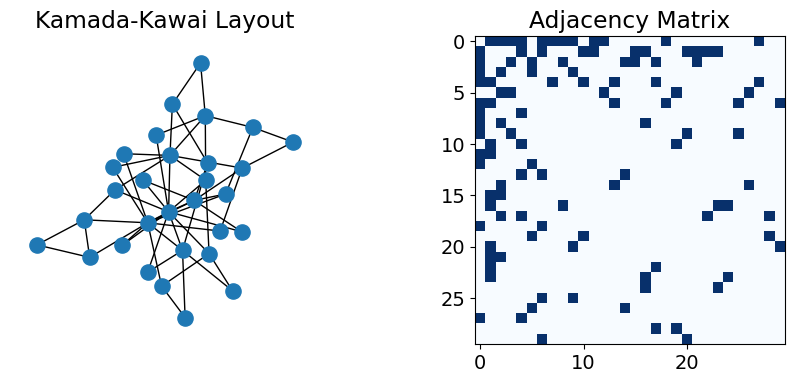

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.barabasi_albert_graph(30, 2)
_, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'wspace': 0.5})
nx.draw_kamada_kawai(G, ax=axes[0], node_size=120)
axes[1].imshow(nx.to_numpy_array(G), aspect='auto', cmap='Blues')
axes[0].set_title("Kamada-Kawai Layout")
axes[1].set_title("Adjacency Matrix")
plt.show()

生成测试结构...
生成的结构: Atoms(symbols='HfOHfOHfOHfOHfOHfOHfOHfO', pbc=True, cell=[[0.0, 5.6, 5.6], [5.6, 0.0, 5.6], [5.6, 5.6, 0.0]])
节点数: 12
边数: 28


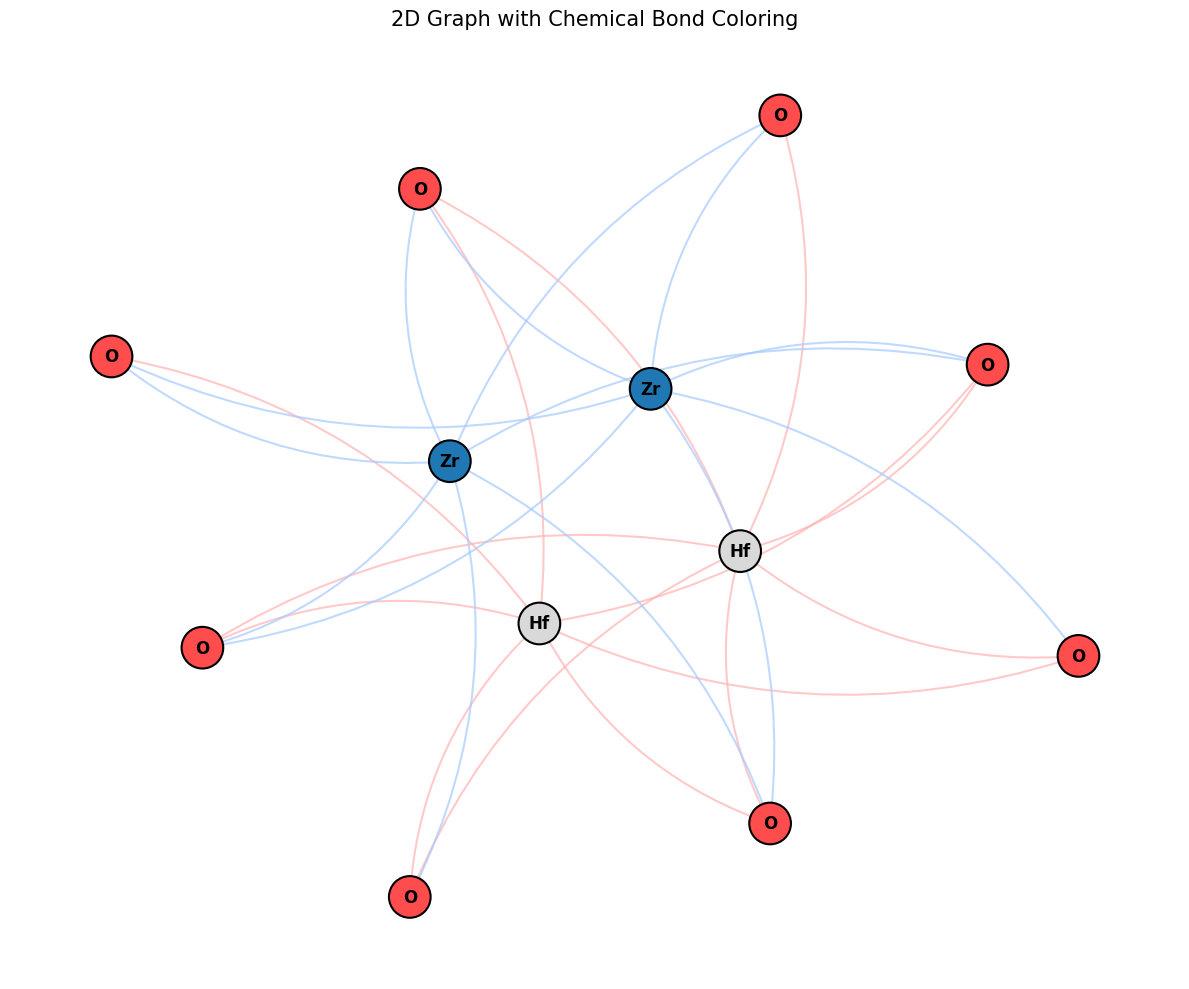

In [42]:
import networkx as nx
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from ase.io import read
from ase.neighborlist import neighbor_list
import numpy as np

# ==========================================
# 1. 读取 VASP 数据 & 构建图
# ==========================================
def load_vasp_as_graph(filepath, cutoff=3.0):
    # 读取结构
    atoms = read(filepath)
    
    # 使用 ASE 的 neighbor_list 处理 PBC
    # 'ij' 表示获取源原子索引 i 和 目标原子索引 j
    # 只要距离 < cutoff，就算作一条边
    src_indices, dst_indices = neighbor_list('ij', atoms, cutoff)
    
    # 创建 NetworkX 图对象
    G = nx.Graph()
    
    # 添加节点 (带有原子类型信息)
    symbols = atoms.get_chemical_symbols()
    positions = atoms.get_positions()
    
    for idx, symbol in enumerate(symbols):
        G.add_node(idx, symbol=symbol, pos=positions[idx])
        
    # 添加边 (基于近邻列表)
    # zip将源和目标配对
    edges = list(zip(src_indices, dst_indices))
    G.add_edges_from(edges)
    
    return G, atoms

# ==========================================
# 2. 可视化：3D 物理空间图
# ==========================================
def plot_3d_crystal_graph(G, atoms):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # 获取节点坐标
    pos = nx.get_node_attributes(G, 'pos')
    xs = [pos[i][0] for i in G.nodes()]
    ys = [pos[i][1] for i in G.nodes()]
    zs = [pos[i][2] for i in G.nodes()]
    
    # 定义颜色 (简单示例：Hf为红色，O为蓝色)
    colors = []
    labels = nx.get_node_attributes(G, 'symbol')
    for idx in G.nodes():
        sym = labels[idx]
        if 'Hf' in sym or 'Zr' in sym: colors.append('red')
        elif 'O' in sym: colors.append('blue')
        else: colors.append('gray')

    # 绘制节点
    ax.scatter(xs, ys, zs, c=colors, s=100, edgecolors='k', depthshade=False)
    
    # 绘制边
    # 注意：在3D图中画跨越边界的边可能会显得很乱，这里直接连线
    for u, v in G.edges():
        x = [pos[u][0], pos[v][0]]
        y = [pos[u][1], pos[v][1]]
        z = [pos[u][2], pos[v][2]]
        
        # 简单过滤：如果边的长度太长（说明跨越了周期性边界），就不画线，避免视觉干扰
        # 这是一个可视化技巧，不影响图的数学结构
        dist = np.linalg.norm(np.array(pos[u]) - np.array(pos[v]))
        if dist < 5.0: 
            ax.plot(x, y, z, c='gray', alpha=0.5, linewidth=1)

    ax.set_xlabel('X (Angstrom)')
    ax.set_ylabel('Y (Angstrom)')
    ax.set_zlabel('Z (Angstrom)')
    ax.set_title('3D Graph Representation (Physical Space)')
    plt.show()

# ==========================================
# 3. 可视化：2D 拓扑结构图 (Force-directed)
# ==========================================
# def plot_2d_topology_optimized(G):
#     plt.figure(figsize=(12, 10)) # 1. 加大画布尺寸
    
#     # ==========================================
#     # 策略 A: 布局优化 (减少拥挤)
#     # ==========================================
#     # 选项 1: Kamada-Kawai (推荐用于晶体，能更好地分开节点)
#     pos = nx.kamada_kawai_layout(G)
    
#     # 选项 2: 如果还是想用 Spring，必须调大 k 值 (k越大，节点排斥力越强)
#     # k = 1.5 / np.sqrt(G.number_of_nodes()) 
#     # pos = nx.spring_layout(G, k=k, iterations=100, seed=42)

#     # ==========================================
#     # 颜色与标签准备
#     # ==========================================
#     colors = []
#     labels = nx.get_node_attributes(G, 'symbol')
#     node_labels = {i: f"{labels[i]}" for i in G.nodes()} # 简化标签，去掉数字可能更清爽，或者保留
    
#     for idx in G.nodes():
#         sym = labels[idx]
#         if 'Hf' in sym: colors.append('#d9d9d9') # 浅灰 (Hf)
#         elif 'Zr' in sym: colors.append('#1f77b4') # 蓝色 (Zr)
#         elif 'O' in sym: colors.append('#ff4d4d') # 红色 (O)
#         else: colors.append('black')

#     # ==========================================
#     # 策略 B: 绘制曲线边 (解决直线重合)
#     # ==========================================
#     # networkx 默认的 draw 不支持曲线，必须把点和边分开画
    
#     # 1. 画边 (Edges) - 使用 arc3 样式实现曲线
#     # rad=0.1 控制弯曲程度，alpha=0.3 让重叠处变淡
#     edges = nx.draw_networkx_edges(
#         G, pos, 
#         edge_color='silver', 
#         width=1.0, 
#         alpha=0.4,  # 透明度很重要
#         connectionstyle="arc3,rad=1" # 【关键】这里设置曲线
#     )
    
#     # 2. 画节点 (Nodes)
#     nodes = nx.draw_networkx_nodes(
#         G, pos, 
#         node_color=colors, 
#         node_size=600, # 稍微调大节点
#         edgecolors='black' # 给节点加个黑边，更清晰
#     )
    
#     # 3. 画标签 (Labels)
#     nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10, font_weight='bold')

#     plt.title("Optimized 2D Graph (Curved Edges & Kamada-Kawai Layout)", fontsize=14)
#     plt.axis('off') # 关闭坐标轴框线
#     plt.tight_layout()
#     plt.show()

# def plot_2d_topology_curved(G):
#     plt.figure(figsize=(12, 10))
    
#     # 1. 布局：使用 Kamada-Kawai 算法把节点尽量拉开
#     # 如果报错，可以换回 spring_layout
#     try:
#         pos = nx.kamada_kawai_layout(G)
#     except:
#         pos = nx.spring_layout(G, k=0.5, iterations=100)

#     # 2. 颜色设置 (保持您之前的逻辑)
#     colors = []
#     labels = nx.get_node_attributes(G, 'symbol')
#     # 简单的节点标签
#     node_labels = {i: labels[i] for i in G.nodes()} 
    
#     for idx in G.nodes():
#         sym = labels[idx]
#         if 'Hf' in sym: colors.append('#d9d9d9')   # 浅灰
#         elif 'Zr' in sym: colors.append('#1f77b4') # 蓝
#         elif 'O' in sym: colors.append('#ff4d4d')  # 红
#         else: colors.append('black')

#     # ==========================================
#     # 【核心修改】绘制曲线边
#     # ==========================================
#     nx.draw_networkx_edges(
#         G, 
#         pos, 
#         edge_color='silver', 
#         width=1.5, 
#         alpha=0.6, 
        
#         # --- 魔法参数开始 ---
#         arrows=True,       # 必须设为 True！这会强制调用 FancyArrowPatch
#         arrowstyle='-',    # 将箭头样式设为短横线（即没有箭头），否则会有箭头
        
#         # arc3,rad=0.2 表示弧度。
#         # 正值向右弯，负值向左弯。0.2 是一个比较优雅的弧度。
#         connectionstyle="arc3,rad=-0.2" 
#         # --- 魔法参数结束 ---
#     )
    
#     # 4. 绘制节点
#     nx.draw_networkx_nodes(
#         G, 
#         pos, 
#         node_color=colors, 
#         node_size=800, 
#         edgecolors='black',
#         linewidths=1.5
#     )
    
#     # 5. 绘制标签
#     nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=12, font_weight='bold')

#     plt.title("Optimized 2D Graph with Curves", fontsize=15)
#     plt.axis('off')
#     plt.tight_layout()
#     plt.show()



# def plot_2d_alternating_curves(G):
#     plt.figure(figsize=(12, 10))
    
#     # 1. 布局计算
#     try:
#         # 尝试使用 Kamada-Kawai (通常对晶体结构效果最好)
#         pos = nx.kamada_kawai_layout(G)
#     except:
#         pos = nx.spring_layout(G, k=0.5, seed=42)

#     # 2. 准备颜色
#     colors = []
#     labels = nx.get_node_attributes(G, 'symbol')
#     node_labels = {i: labels[i] for i in G.nodes()} 
    
#     for idx in G.nodes():
#         sym = labels[idx]
#         if 'Hf' in sym: colors.append('#d9d9d9')   # 浅灰
#         elif 'Zr' in sym: colors.append('#1f77b4') # 蓝
#         elif 'O' in sym: colors.append('#ff4d4d')  # 红
#         else: colors.append('black')

#     # ==========================================
#     # 【核心技巧】分批绘制边 (Split and Draw)
#     # ==========================================
    
#     # 获取所有边的列表
#     all_edges = list(G.edges())
    
#     # 将边分为两组：
#     # edges_A: 索引为 0, 2, 4... 的边
#     # edges_B: 索引为 1, 3, 5... 的边
#     edges_A = all_edges[::2]
#     edges_B = all_edges[1::2]
    
#     # 第一批：向右弯曲 (rad > 0)
#     nx.draw_networkx_edges(
#         G, pos, 
#         edgelist=edges_A,      # 只画这一半
#         edge_color='silver', 
#         width=1.5, 
#         # alpha=0.5, 
#         arrows=True, arrowstyle='-', # 强制开启曲线模式
#         connectionstyle="arc3,rad=0.2" # 正弧度
#     )
    
#     # 第二批：向左弯曲 (rad < 0)
#     nx.draw_networkx_edges(
#         G, pos, 
#         edgelist=edges_B,      # 画另一半
#         edge_color='silver', 
#         width=1.5, 
#         # alpha=0.5, 
#         arrows=True, arrowstyle='-', # 强制开启曲线模式
#         connectionstyle="arc3,rad=-0.2" # 负弧度 (反向弯曲)
#     )

#     # 3. 绘制节点和标签 (最后画，盖在边上面)
#     nx.draw_networkx_nodes(
#         G, pos, 
#         node_color=colors, 
#         node_size=800, 
#         edgecolors='black',
#         linewidths=1.5
#     )
    
#     nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=12, font_weight='bold')

#     plt.title("2D Graph with Alternating Curves (Left/Right)", fontsize=15)
#     plt.axis('off')
#     plt.tight_layout()
#     plt.show()



def plot_2d_colored_bonds(G):
    plt.figure(figsize=(12, 10))
    
    # 1. 布局计算
    try:
        pos = nx.kamada_kawai_layout(G)
    except:
        pos = nx.spring_layout(G, k=0.5, seed=42)

    # 2. 准备节点颜色与标签
    labels = nx.get_node_attributes(G, 'symbol')
    node_colors = []
    node_labels = {}
    for idx in G.nodes():
        sym = labels[idx]
        node_labels[idx] = sym # 标签只显示元素名，更清爽
        if 'Hf' in sym: node_colors.append('#d9d9d9') # 浅灰
        elif 'Zr' in sym: node_colors.append('#1f77b4') # 蓝
        elif 'O' in sym: node_colors.append('#ff4d4d')  # 红
        else: node_colors.append('black')

    # ==========================================
    # 【核心改进】准备边颜色列表
    # ==========================================
    edge_colors = []
    all_edges = list(G.edges())
    
    for u, v in all_edges:
        sym_u = labels[u]
        sym_v = labels[v]
        
        # 判断边的两端连接的是什么原子
        # Hf-O 键 -> 淡红色
        if ('Hf' in sym_u and 'O' in sym_v) or ('O' in sym_u and 'Hf' in sym_v):
            edge_colors.append('#ffb3b3') 
        # Zr-O 键 -> 淡蓝色
        elif ('Zr' in sym_u and 'O' in sym_v) or ('O' in sym_u and 'Zr' in sym_v):
            edge_colors.append('#a6c9ff')
        # 其他情况（如金属间连接，如果cutoff很大） -> 极淡灰色作为背景
        else:
            edge_colors.append('#e0e0e0')

    # ==========================================
    # 分批绘制带颜色的曲线边
    # ==========================================
    mid = len(all_edges) // 2
    
    # 第一批：向右弯，使用对应的颜色列表
    nx.draw_networkx_edges(
        G, pos, 
        edgelist=all_edges[:mid],
        edge_color=edge_colors[:mid], # 应用颜色
        width=1.5, 
        alpha=0.7, # 透明度可以稍微高一点，因为有颜色区分了
        arrows=True, arrowstyle='-',
        connectionstyle="arc3,rad=0.2"
    )
    
    # 第二批：向左弯，使用对应的颜色列表
    nx.draw_networkx_edges(
        G, pos, 
        edgelist=all_edges[mid:],
        edge_color=edge_colors[mid:], # 应用颜色
        width=1.5, 
        alpha=0.7,
        arrows=True, arrowstyle='-',
        connectionstyle="arc3,rad=-0.2"
    )

    # 3. 绘制节点和标签 (最后画，盖在边上面)
    nx.draw_networkx_nodes(
        G, pos, 
        node_color=node_colors, 
        node_size=900, # 节点稍微大一点
        edgecolors='black',
        linewidths=1.5
    )
    
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=12, font_weight='bold')

    plt.title("2D Graph with Chemical Bond Coloring", fontsize=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
# --- 调用方法 ---
# if __name__ == "__main__":
#     # 假设您已经有 G 对象，且想查看索引为 0 的原子 (比如 Hf0)
#     # 您可以先打印 G.nodes(data=True) 看看哪个索引对应哪个原子
#     plot_focus_graph(G, focus_node_idx=0)




# --- 使用方法 ---
# 在原来的 main 函数中，替换 plot_2d_topology(G) 为：
# plot_2d_topology_optimized(G)
# ==========================================
# 主程序
# ==========================================
# ==========================================
# 主程序
# ==========================================
if __name__ == "__main__":
    # 【修正部分】
    from ase.build import bulk
    
    print("生成测试结构...")
    
    # 方案 1: 使用 ASE 内置支持的 'rocksalt' (岩盐结构) 来模拟二元晶体
    # 我们生成 NaCl 结构，然后把原子强行改名为 Hf 和 O，以便适配上面的颜色代码
    atoms = bulk('NaCl', 'rocksalt', a=5.6)
    
    # 将 Na 替换为 Hf，将 Cl 替换为 O (为了让上面的可视化代码显色)
    symbols = atoms.get_chemical_symbols()
    new_symbols = ['Hf' if s == 'Na' else 'O' for s in symbols]
    atoms.set_chemical_symbols(new_symbols)
    
    # 扩胞 (Supercell) 让图看起来更丰富
    atoms = atoms * (2, 2, 2)
    
    print(f"生成的结构: {atoms}")

    # 1. 加载图
    # Hf-O 键长通常在 2.0-2.2 左右，考虑到扩胞后的次近邻，cutoff 设为 3.0 是合适的
    G, atoms = load_vasp_as_graph('vasp_test/CONTCAR_pca21', cutoff=2.3)
    # 注意：这里并没有真正读取文件，因为 load_vasp_as_graph 第一行是 read()
    # 为了代码逻辑通顺，我们直接把上面的 atoms 传给转换函数
    # 修改 load_vasp_as_graph 函数，让它支持直接传入 atoms 对象
    
    # --- 修正 load_vasp_as_graph 调用逻辑 ---
    # 为了不改动上面太多，我们手动执行转换逻辑：
    src_indices, dst_indices = neighbor_list('ij', atoms, cutoff=2.3)
    G = nx.Graph()
    symbols = atoms.get_chemical_symbols()
    positions = atoms.get_positions()
    for idx, symbol in enumerate(symbols):
        G.add_node(idx, symbol=symbol, pos=positions[idx])
    edges = list(zip(src_indices, dst_indices))
    G.add_edges_from(edges)
    # ----------------------------------------
    
    print(f"节点数: {G.number_of_nodes()}")
    print(f"边数: {G.number_of_edges()}")
    
    # 2. 绘制 2D 拓扑图
    plot_2d_colored_bonds(G)
    
    # 3. 绘制 3D 物理图
    # plot_3d_crystal_graph(G, atoms)

C:\Users\23210\AppData\Local\Temp\ipykernel_28824\2984759489.py:9: FutureWarning: with_local_env_strategy is deprecated, and will be removed on 2025-03-20
Use from_local_env_strategy in pymatgen.analysis.graphs instead.
Deprecated on 2024-03-29.
  sg = StructureGraph.with_local_env_strategy(structure, CrystalNN())


[(0, {}), (1, {}), (2, {}), (3, {}), (4, {}), (5, {}), (6, {}), (7, {}), (8, {}), (9, {}), (10, {}), (11, {})]
[(0, 10, {'to_jimage': (-1, -1, 1)}), (0, 5, {'to_jimage': (-1, 0, 0)}), (0, 8, {'to_jimage': (0, -1, 0)}), (0, 6, {'to_jimage': (0, -1, 1)}), (0, 7, {'to_jimage': (0, 0, 1)}), (0, 9, {'to_jimage': (0, 0, 0)}), (0, 11, {'to_jimage': (-1, 0, 1)}), (1, 8, {'to_jimage': (1, 0, 0)}), (1, 7, {'to_jimage': (1, 0, 0)}), (1, 10, {'to_jimage': (0, 0, 0)}), (1, 4, {'to_jimage': (0, 0, 0)}), (1, 5, {'to_jimage': (0, 0, 0)}), (1, 11, {'to_jimage': (0, 0, 0)}), (1, 9, {'to_jimage': (1, 0, 0)}), (2, 6, {'to_jimage': (0, 0, 1)}), (2, 9, {'to_jimage': (0, 0, 0)}), (2, 4, {'to_jimage': (0, 0, 0)}), (2, 11, {'to_jimage': (0, 0, 1)}), (2, 10, {'to_jimage': (0, 0, 1)}), (2, 7, {'to_jimage': (0, 0, 1)}), (2, 5, {'to_jimage': (0, 0, 0)}), (3, 4, {'to_jimage': (0, -1, 0)}), (3, 11, {'to_jimage': (0, 0, 0)}), (3, 6, {'to_jimage': (0, -1, 0)}), (3, 9, {'to_jimage': (0, 0, 0)}), (3, 8, {'to_jimage': (0

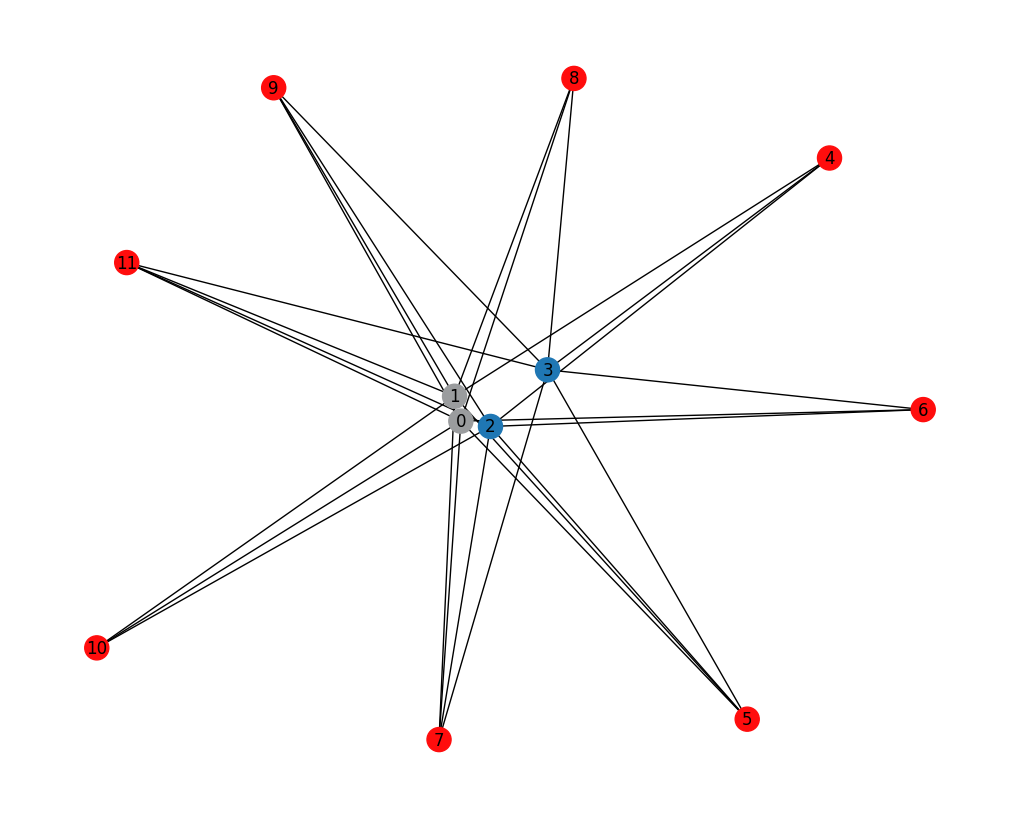

In [26]:
from pymatgen.core import Structure
from pymatgen.analysis.graphs import StructureGraph
from pymatgen.analysis.local_env import CrystalNN
import networkx as nx
import matplotlib.pyplot as plt

structure = Structure.from_file("vasp_test/CONTCAR_pca21")   # 或 POSCAR

sg = StructureGraph.with_local_env_strategy(structure, CrystalNN())

nx_graph = sg.graph
print(nx_graph.nodes(data=True))
print(nx_graph.edges(data=True))


node_colors = []
for node in nx_graph.nodes():
    element = structure[node].species_string
    if element == 'Hf':
        node_colors.append('#9a9c9e')  # gray
    elif element == 'Zr':
        node_colors.append('#1f77b4')  # blue
    elif element == 'O':
        node_colors.append('#ff0d0d')  # red
    else:
        node_colors.append('darkgray')  # default

plt.figure(figsize=(10, 8))
nx.draw(nx_graph, with_labels=True, node_color=node_colors, font_size=12, arrowstyle='-', arrowsize=12)

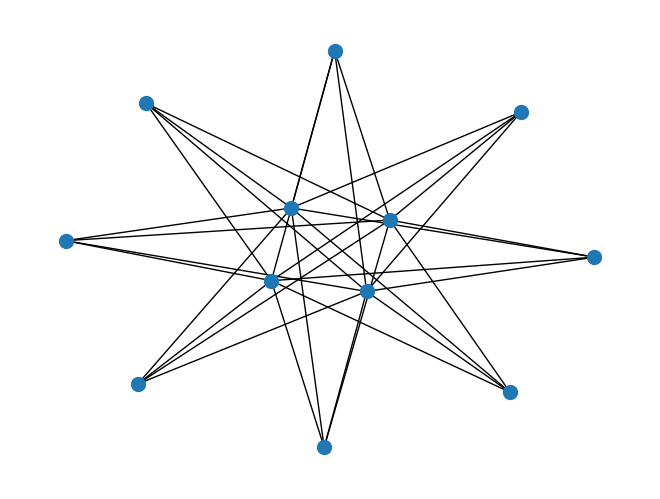

In [17]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

for i, site in enumerate(structure):
    G.add_node(i, element=site.species_string)

neighbors = structure.get_all_neighbors(r=2.5)  # 自定义 cutoff

for i, neigh_list in enumerate(neighbors):
    for neigh in neigh_list:
        j = neigh.index
        if i < j:
            G.add_edge(i, j)

# 可视化
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=False, node_size=100)
plt.show()


In [ ]:
from megnet.data.crystal import CrystalGraph
from pymatgen.core import Structure

structure = Structure.from_file("CONTCAR")

graph = CrystalGraph().convert(structure)



ModuleNotFoundError: No module named 'megnet'

In [ ]:
def plot_2d_topology_optimized(G):
    plt.figure(figsize=(12, 10)) # 1. 加大画布尺寸
    
    # ==========================================
    # 策略 A: 布局优化 (减少拥挤)
    # ==========================================
    # 选项 1: Kamada-Kawai (推荐用于晶体，能更好地分开节点)
    pos = nx.kamada_kawai_layout(G)
    
    # 选项 2: 如果还是想用 Spring，必须调大 k 值 (k越大，节点排斥力越强)
    # k = 1.5 / np.sqrt(G.number_of_nodes()) 
    # pos = nx.spring_layout(G, k=k, iterations=100, seed=42)

    # ==========================================
    # 颜色与标签准备
    # ==========================================
    colors = []
    labels = nx.get_node_attributes(G, 'symbol')
    node_labels = {i: f"{labels[i]}" for i in G.nodes()} # 简化标签，去掉数字可能更清爽，或者保留
    
    for idx in G.nodes():
        sym = labels[idx]
        if 'Hf' in sym: colors.append('#d9d9d9') # 浅灰 (Hf)
        elif 'Zr' in sym: colors.append('#1f77b4') # 蓝色 (Zr)
        elif 'O' in sym: colors.append('#ff4d4d') # 红色 (O)
        else: colors.append('black')

    # ==========================================
    # 策略 B: 绘制曲线边 (解决直线重合)
    # ==========================================
    # networkx 默认的 draw 不支持曲线，必须把点和边分开画
    
    # 1. 画边 (Edges) - 使用 arc3 样式实现曲线
    # rad=0.1 控制弯曲程度，alpha=0.3 让重叠处变淡
    edges = nx.draw_networkx_edges(
        G, pos, 
        edge_color='silver', 
        width=1.0, 
        alpha=0.4,  # 透明度很重要
        connectionstyle="arc3,rad=0.1" # 【关键】这里设置曲线
    )
    
    # 2. 画节点 (Nodes)
    nodes = nx.draw_networkx_nodes(
        G, pos, 
        node_color=colors, 
        node_size=600, # 稍微调大节点
        edgecolors='black' # 给节点加个黑边，更清晰
    )
    
    # 3. 画标签 (Labels)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10, font_weight='bold')

    plt.title("Optimized 2D Graph (Curved Edges & Kamada-Kawai Layout)", fontsize=14)
    plt.axis('off') # 关闭坐标轴框线
    plt.tight_layout()
    plt.show()

# --- 使用方法 ---
# 在原来的 main 函数中，替换 plot_2d_topology(G) 为：
# plot_2d_topology_optimized(G)